# PyTorch DNN (은닉층 여러 개) - EuroSAT 이미지 분류
Dense 은닉층 3개(512-256-128)를 쌓은 구조

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil

SPLIT_DIR = '/content/eurosat_split'
DRIVE_ZIP = '/content/drive/MyDrive/eurosat_split.zip'

if not os.path.exists(SPLIT_DIR) and os.path.exists(DRIVE_ZIP):
    shutil.unpack_archive(DRIVE_ZIP, SPLIT_DIR)
    print('Drive에서 압축 해제 완료')
else:
    print('SPLIT_DIR:', SPLIT_DIR)

Mounted at /content/drive
Drive에서 압축 해제 완료


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('사용 device:', device)

IMG_SIZE = (64, 64)
BATCH_SIZE = 32

transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
])

train_dataset = datasets.ImageFolder(os.path.join(SPLIT_DIR, 'train'), transform=transform)
val_dataset = datasets.ImageFolder(os.path.join(SPLIT_DIR, 'val'), transform=transform)
test_dataset = datasets.ImageFolder(os.path.join(SPLIT_DIR, 'test'), transform=transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

num_classes = len(train_dataset.classes)
print('클래스 수:', num_classes)

사용 device: cuda
클래스 수: 10


## DNN 모델 정의

In [ ]:
class DNN(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.net(x)

def _init_weights(m):
    if isinstance(m, (nn.Linear, nn.Conv2d)):
        nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
        if m.bias is not None:
            nn.init.zeros_(m.bias)

input_dim = IMG_SIZE[0] * IMG_SIZE[1] * 3
model = DNN(input_dim, num_classes).to(device)
model.apply(_init_weights)

num_params = sum(p.numel() for p in model.parameters())
print(model)
print(f'파라미터 수: {num_params:,}')

DNN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=12288, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.3, inplace=False)
    (7): Linear(in_features=256, out_features=128, bias=True)
    (8): ReLU()
    (9): Dropout(p=0.3, inplace=False)
    (10): Linear(in_features=128, out_features=10, bias=True)
  )
)
파라미터 수: 6,457,482


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=3)

def run_epoch(model, loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if train:
                optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            if train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += images.size(0)
    return total_loss / total, correct / total

In [ ]:
import time
import copy

MAX_EPOCHS = 50
PATIENCE = 5

history = {'loss': [], 'val_loss': [], 'accuracy': [], 'val_accuracy': []}
best_val_loss = float('inf')
best_state = None
epochs_no_improve = 0

start_time = time.time()

for epoch in range(MAX_EPOCHS):
    train_loss, train_acc = run_epoch(model, train_loader, train=True)
    val_loss, val_acc = run_epoch(model, val_loader, train=False)
    scheduler.step(val_loss)

    history['loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['accuracy'].append(train_acc)
    history['val_accuracy'].append(val_acc)

    print(f'Epoch {epoch+1}: loss={train_loss:.4f} acc={train_acc:.4f} val_loss={val_loss:.4f} val_acc={val_acc:.4f}')

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print('EarlyStopping 발동')
            break

model.load_state_dict(best_state)
training_time = time.time() - start_time
print(f'학습 시간: {training_time:.1f}초')

Epoch 1: loss=2.2831 acc=0.1690 val_loss=1.9680 val_acc=0.2598
Epoch 2: loss=2.0097 acc=0.2076 val_loss=1.8339 val_acc=0.2657
Epoch 3: loss=1.9893 acc=0.2213 val_loss=1.7903 val_acc=0.3528
Epoch 4: loss=1.9665 acc=0.2401 val_loss=1.8715 val_acc=0.2802
Epoch 5: loss=1.9510 acc=0.2465 val_loss=1.7667 val_acc=0.3538
Epoch 6: loss=1.9246 acc=0.2554 val_loss=1.7619 val_acc=0.2943
Epoch 7: loss=1.9027 acc=0.2676 val_loss=1.9046 val_acc=0.2533
Epoch 8: loss=1.8707 acc=0.2785 val_loss=1.8125 val_acc=0.2812
Epoch 9: loss=1.8700 acc=0.2752 val_loss=1.8563 val_acc=0.2489
Epoch 10: loss=1.8686 acc=0.2801 val_loss=1.9560 val_acc=0.2079
Epoch 11: loss=1.8512 acc=0.2893 val_loss=1.7873 val_acc=0.2830
EarlyStopping 발동
학습 시간: 144.3초


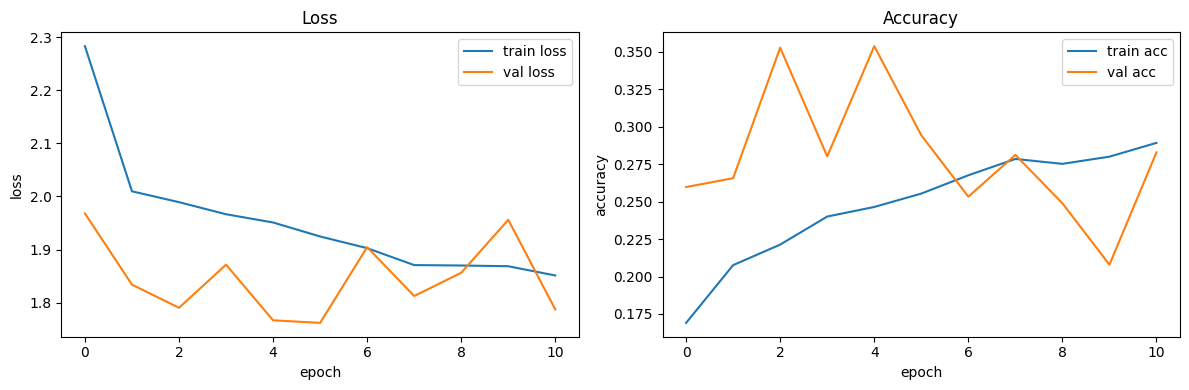

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history['loss'], label='train loss')
axes[0].plot(history['val_loss'], label='val loss')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('loss'); axes[0].legend(); axes[0].set_title('Loss')
axes[1].plot(history['accuracy'], label='train acc')
axes[1].plot(history['val_accuracy'], label='val acc')
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('accuracy'); axes[1].legend(); axes[1].set_title('Accuracy')
plt.tight_layout(); plt.show()

In [ ]:
test_loss, test_acc = run_epoch(model, test_loader, train=False)
print(f'Test accuracy: {test_acc:.4f}')
print(f'Test loss: {test_loss:.4f}')
print(f'파라미터 수: {num_params:,}')

Test accuracy: 0.2906
Test loss: 1.7606
파라미터 수: 6,457,482


In [ ]:
import pandas as pd

RESULTS_PATH = '/content/drive/MyDrive/model_results.csv'
row = {
    'model': 'DNN', 'framework': 'PyTorch',
    'test_accuracy': test_acc, 'test_loss': test_loss,
    'num_params': num_params, 'training_time_sec': training_time,
    'epochs_ran': len(history['loss']),
}

if os.path.exists(RESULTS_PATH):
    results_df = pd.read_csv(RESULTS_PATH)
    results_df = results_df[~((results_df['model'] == row['model']) & (results_df['framework'] == row['framework']))]
    results_df = pd.concat([results_df, pd.DataFrame([row])], ignore_index=True)
else:
    results_df = pd.DataFrame([row])

results_df.to_csv(RESULTS_PATH, index=False)
results_df

,model,framework,test_accuracy,test_loss,num_params,training_time_sec,epochs_ran
0,CNN,PyTorch,0.947407,0.190860,2193674,513.813921,34
1,ANN,Keras,0.273827,1.791635,3148554,65.389723,28
2,DNN,Keras,0.390864,1.600345,6457482,71.961101,23
3,CNN,Keras,0.908395,0.352731,2194122,95.166941,17
4,ANN,PyTorch,0.216296,1.917291,3148554,130.308418,11
5,DNN,PyTorch,0.290617,1.760557,6457482,144.349892,11
